# Module 5 — Notebook 03: Martin 2019 Crohn's ileum (load + QC)

**Role in the paper.** The full-circuit replication cohort: immune-rich lamina
propria with RAW 10x counts (so DESeq2 is possible here, unlike Kinchen), and
the cohort where the GIMATS anti-TNF resistance module was defined.

**Design (from the GEO series record, verified Nov 22, 2026).** 22 ileal tissue
samples: 11 involved (inflamed) + 11 uninvolved from Crohn's patients; no
healthy controls — the contrast is involved vs uninvolved. 9 PBMC samples in
the series are excluded (different compartment, added later).

Analyses of public datasets; all data credited to original authors.


In [1]:
import os, re, tarfile, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import scanpy as sc

base = os.path.expanduser("~/Documents/immune-endotypes/data/martin_2019")
tar_path = os.path.join(base, "GSE134809_RAW.tar")
ext = os.path.join(base, "extracted")
print("tar exists:", os.path.exists(tar_path))
if not os.path.exists(ext):
    os.makedirs(ext)
    with tarfile.open(tar_path) as tf:
        tf.extractall(ext)
    print("extracted")
names = sorted(os.listdir(ext))
print(len(names), "files; first 12:")
for n in names[:12]:
    print(" ", n)


tar exists: True
extracted
93 files; first 12:
  GSM3972009_69_barcodes.tsv.gz
  GSM3972009_69_genes.tsv.gz
  GSM3972009_69_matrix.mtx.gz
  GSM3972010_68_barcodes.tsv.gz
  GSM3972010_68_genes.tsv.gz
  GSM3972010_68_matrix.mtx.gz
  GSM3972011_122_barcodes.tsv.gz
  GSM3972011_122_genes.tsv.gz
  GSM3972011_122_matrix.mtx.gz
  GSM3972012_123_barcodes.tsv.gz
  GSM3972012_123_genes.tsv.gz
  GSM3972012_123_matrix.mtx.gz


In [2]:
# Sample map from the GEO series record (GSM -> tissue status, patient no.)
ILEAL = {
 "GSM3972009": ("Involved", 69),  "GSM3972011": ("Involved", 122),
 "GSM3972013": ("Involved", 128), "GSM3972016": ("Involved", 138),
 "GSM3972017": ("Involved", 158), "GSM3972020": ("Involved", 181),
 "GSM3972022": ("Involved", 187), "GSM3972024": ("Involved", 190),
 "GSM3972026": ("Involved", 193), "GSM3972028": ("Involved", 196),
 "GSM3972030": ("Involved", 209),
 "GSM3972010": ("Uninvolved", 68),  "GSM3972012": ("Uninvolved", 123),
 "GSM3972014": ("Uninvolved", 129), "GSM3972015": ("Uninvolved", 135),
 "GSM3972018": ("Uninvolved", 159), "GSM3972019": ("Uninvolved", 180),
 "GSM3972021": ("Uninvolved", 186), "GSM3972023": ("Uninvolved", 189),
 "GSM3972025": ("Uninvolved", 192), "GSM3972027": ("Uninvolved", 195),
 "GSM3972029": ("Uninvolved", 208),
}
from collections import defaultdict
by_gsm = defaultdict(dict)
for n in names:
    m = re.match(r"(GSM\d+)", n)
    if not m:
        continue
    gsm = m.group(1)
    low = n.lower()
    if "matrix" in low and low.endswith((".mtx", ".mtx.gz")):
        by_gsm[gsm]["matrix"] = n
    elif "barcode" in low:
        by_gsm[gsm]["barcodes"] = n
    elif "feature" in low or "gene" in low:
        by_gsm[gsm]["features"] = n
print("samples with a matrix file:", len(by_gsm))
print("ileal samples found:", sum(1 for g in by_gsm if g in ILEAL), "of", len(ILEAL))
incomplete = {g: sorted(v) for g, v in by_gsm.items() if len(v) < 3}
print("incomplete triplets:", incomplete)


samples with a matrix file: 31
ileal samples found: 22 of 22
incomplete triplets: {}


If any ileal sample is incomplete or missing, stop and show the file list —
the loader below assumes one matrix/barcodes/features triplet per GSM.


In [3]:
import scipy.io as sio
import scipy.sparse as sp

def load_sample(gsm):
    f = by_gsm[gsm]
    X = sio.mmread(os.path.join(ext, f["matrix"])).tocsr()  # genes x cells
    bc = pd.read_csv(os.path.join(ext, f["barcodes"]), header=None, sep="\t")[0].astype(str)
    ft = pd.read_csv(os.path.join(ext, f["features"]), header=None, sep="\t")
    genes = ft[1].astype(str) if ft.shape[1] >= 2 else ft[0].astype(str)
    ad = sc.AnnData(X.T.tocsr())
    ad.obs_names = [f"{gsm}_{b}" for b in bc]
    ad.var_names = genes
    ad.var_names_make_unique()
    cond, pat = ILEAL[gsm]
    ad.obs["condition"] = cond
    ad.obs["patient"] = str(pat)
    ad.obs["sample"] = gsm
    ad.obs["dataset"] = "Martin2019"
    return ad

ads = []
for gsm in sorted(ILEAL):
    if gsm in by_gsm:
        a = load_sample(gsm)
        print(gsm, ILEAL[gsm], a.shape)
        ads.append(a)
adata = sc.concat(ads, join="outer")
adata.obs_names_make_unique()
print(adata)
print(adata.obs["condition"].value_counts())


GSM3972009 ('Involved', 69) (737280, 33694)
GSM3972010 ('Uninvolved', 68) (737280, 33694)
GSM3972011 ('Involved', 122) (737280, 33694)
GSM3972012 ('Uninvolved', 123) (737280, 33694)
GSM3972013 ('Involved', 128) (737280, 33694)
GSM3972014 ('Uninvolved', 129) (737280, 33694)
GSM3972015 ('Uninvolved', 135) (737280, 33694)
GSM3972016 ('Involved', 138) (737280, 33694)
GSM3972017 ('Involved', 158) (737280, 33694)
GSM3972018 ('Uninvolved', 159) (737280, 33694)
GSM3972019 ('Uninvolved', 180) (737280, 33694)
GSM3972020 ('Involved', 181) (737280, 33694)
GSM3972021 ('Uninvolved', 186) (737280, 33694)
GSM3972022 ('Involved', 187) (737280, 33694)
GSM3972023 ('Uninvolved', 189) (737280, 33694)
GSM3972024 ('Involved', 190) (737280, 33694)
GSM3972025 ('Uninvolved', 192) (737280, 33694)
GSM3972026 ('Involved', 193) (737280, 33694)
GSM3972027 ('Uninvolved', 195) (737280, 33694)
GSM3972028 ('Involved', 196) (737280, 33694)
GSM3972029 ('Uninvolved', 208) (737280, 33694)
GSM3972030 ('Involved', 209) (73728

In [4]:
# QC — raw counts here, module 1 gates
adata.var["mt"] = adata.var_names.str.startswith("MT-")
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt"], inplace=True, percent_top=None)
print(adata.obs[["n_genes_by_counts", "pct_counts_mt"]].describe())
adata.layers["counts"] = adata.X.copy()
adata = adata[(adata.obs["n_genes_by_counts"] > 200) & (adata.obs["pct_counts_mt"] < 50)].copy()
sc.pp.filter_genes(adata, min_cells=3)
print("after QC:", adata.shape)


       n_genes_by_counts  pct_counts_mt
count       1.622016e+07   4.414960e+06
mean        6.663201e+00   1.691616e+01
std         7.762232e+01   3.258078e+01
min         0.000000e+00   0.000000e+00
25%         0.000000e+00   0.000000e+00
50%         0.000000e+00   0.000000e+00
75%         1.000000e+00   1.428571e+01
max         7.706000e+03   1.000000e+02
after QC: (115029, 25356)


leiden clusters: 15


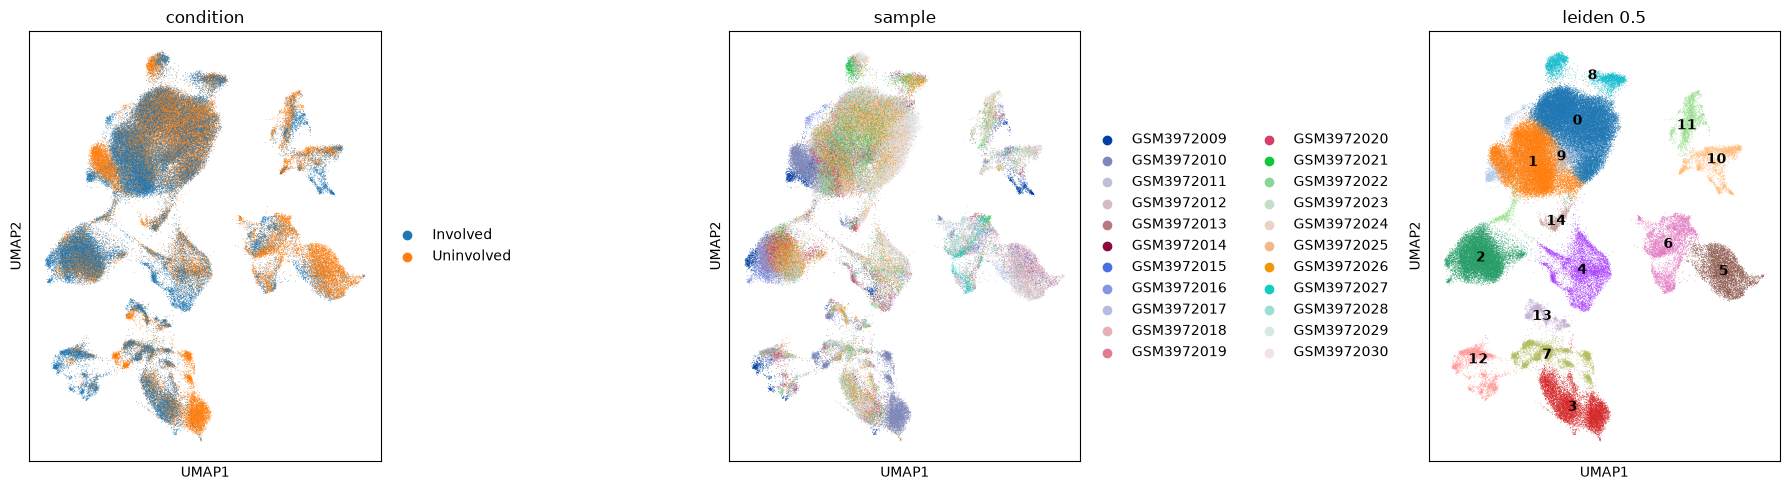

In [5]:
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
sc.pp.highly_variable_genes(adata, n_top_genes=3000, batch_key="sample")
sc.tl.pca(adata, n_comps=50)
sc.pp.neighbors(adata, n_pcs=40)
sc.tl.umap(adata)
sc.tl.leiden(adata, resolution=0.5, key_added="leiden_0.5")
print("leiden clusters:", adata.obs["leiden_0.5"].nunique())
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sc.pl.umap(adata, color="condition", ax=axes[0], show=False, title="condition")
sc.pl.umap(adata, color="sample", ax=axes[1], show=False, title="sample")
sc.pl.umap(adata, color="leiden_0.5", ax=axes[2], show=False, title="leiden 0.5", legend_loc="on data")
plt.tight_layout(); plt.savefig("../figures/martin_umap_overview.png", dpi=130); plt.show()


markers present: ['EPCAM', 'COL1A1', 'DCN', 'PECAM1', 'PTPRC', 'CD3D', 'MS4A1', 'JCHAIN', 'LYZ', 'S100A8', 'CD14', 'IL7R']


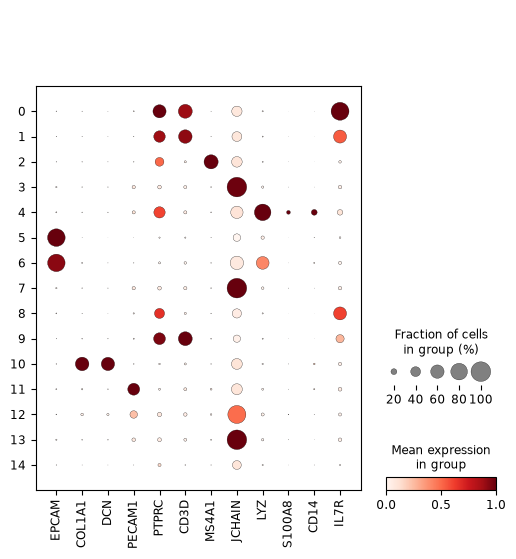

watch present: ['IL11', 'IL13RA2', 'CHI3L1', 'OSMR', 'OSM', 'SIGIRR', 'IL1B', 'IL1R1', 'MMP3']


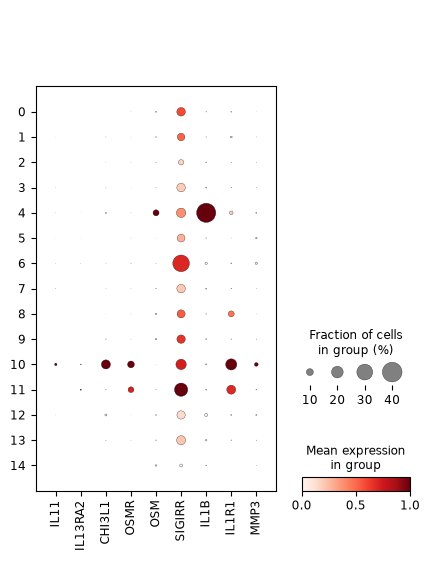

saved adata_martin_qc.h5ad


In [6]:
markers = ["EPCAM", "MUC2", "COL1A1", "DCN", "PECAM1", "PTPRC", "CD3D", "MS4A1",
           "JCHAIN", "LYZ", "S100A8", "CD14", "IL7R"]
present = [g for g in markers if g in adata.var_names]
print("markers present:", present)
sc.pl.dotplot(adata, present, groupby="leiden_0.5", standard_scale="var")
watch = ["IL11", "IL13RA2", "CHI3L1", "OSMR", "OSM", "SIGIRR", "IL1B", "IL1R1", "MMP3"]
watch = [g for g in watch if g in adata.var_names]
print("watch present:", watch)
sc.pl.dotplot(adata, watch, groupby="leiden_0.5", standard_scale="var")
adata.write(os.path.expanduser("~/Documents/immune-endotypes/data/martin_2019/adata_martin_qc.h5ad"))
print("saved adata_martin_qc.h5ad")


## Read-out (fill in after running)

- Compartments present (this cohort should have the full lamina propria:
  epithelial, fibroblast, endothelial, T, B/plasma, myeloid)?
- Inflammatory fibroblasts and inflammatory monocytes: which clusters, and are
  they involved-enriched?
- OSM/OSMR and IL1B/SIGIRR placement vs Smillie module 1?
- Next: notebook 04 — LIANA per condition on Martin (full-circuit replication);
  notebook 05 — human integration; notebook 06 — Kinchen mouse arm.
